In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [28]:
df = pd.read_csv("../data/concrete_data_folds.csv")

train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Train:", train_df.shape)
print("Test :", test_df.shape)

Train: (800, 16)
Test : (205, 16)


In [29]:
# log(age) straightens the curing curve. Age is always >= 1, so log is safe.
train_df["log_age"] = np.log(train_df["age"])
test_df["log_age"] = np.log(test_df["age"])

In [30]:
# Raw "age" is replaced by "log_age".
# mix_id, split and fold are NOT features.
features = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_aggregate", "fine_aggregate", "log_age"]
target = "strength"

X_train = train_df[features]
y_train = train_df[target]     # target is NOT scaled
X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (800, 8)  X_test: (205, 8)


In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # learn median and IQR from train only
X_test_scaled = scaler.transform(X_test)         # apply the same values to test

X_train_scaled = pd.DataFrame(X_train_scaled, columns=features)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=features)

X_train_scaled.describe().T[["50%", "min", "max"]].round(2)

,50%,min,max
cement,-0.07,-1.70,2.42
slag,-0.61,-0.82,3.24
fly_ash,-0.84,-0.84,2.31
water,0.13,-2.78,3.16
superplasticizer,0.04,-1.00,4.57
coarse_aggregate,-0.07,-2.22,2.18
fine_aggregate,0.11,-2.22,2.24
log_age,0.15,-2.64,2.30


In [32]:
# Each fold: train on the other 4 folds, validate on this fold
cv_splits = []
for fold in ["fold_1", "fold_2", "fold_3", "fold_4", "fold_5"]:
    train_index = train_df.index[train_df["fold"] != fold].tolist()
    val_index = train_df.index[train_df["fold"] == fold].tolist()
    cv_splits.append((train_index, val_index))

for i, (tr, val) in enumerate(cv_splits, start=1):
    print("fold_" + str(i), "-> train:", len(tr), " validation:", len(val))

fold_1 -> train: 646  validation: 154
fold_2 -> train: 643  validation: 157
fold_3 -> train: 633  validation: 167
fold_4 -> train: 655  validation: 145
fold_5 -> train: 623  validation: 177


In [33]:
def evaluate(name, model):
    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    return {
        "model": name,
        "train_R2": r2_score(y_train, train_pred),
        "test_R2": r2_score(y_test, test_pred),
        "train_RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "test_RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "train_MAE": mean_absolute_error(y_train, train_pred),
        "test_MAE": mean_absolute_error(y_test, test_pred),
    }

In [34]:
baseline_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
}

baseline_results = []
for name, model in baseline_models.items():
    baseline_results.append(evaluate(name, model))

baseline_df = pd.DataFrame(baseline_results).set_index("model").round(3)
baseline_df

,train_R2,test_R2,train_RMSE,test_RMSE,train_MAE,test_MAE
model,,,,,,
Linear Regression,0.825,0.751,6.838,7.967,5.299,6.124
Ridge,0.825,0.750,6.839,7.983,5.302,6.129
Lasso,0.823,0.741,6.880,8.114,5.349,6.166


In [35]:
advanced_models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR (RBF)": SVR(kernel="rbf", C=100, epsilon=0.5),
}

advanced_results = []
for name, model in advanced_models.items():
    advanced_results.append(evaluate(name, model))

advanced_df = pd.DataFrame(advanced_results).set_index("model").round(3)
advanced_df

,train_R2,test_R2,train_RMSE,test_RMSE,train_MAE,test_MAE
model,,,,,,
Decision Tree,1.000,0.680,0.216,9.028,0.025,6.254
Random Forest,0.990,0.823,1.665,6.713,1.195,4.653
Gradient Boosting,0.953,0.827,3.564,6.630,2.713,4.868
XGBoost,0.996,0.836,1.079,6.469,0.720,4.419
KNN,0.915,0.760,4.760,7.810,3.478,5.396
SVR (RBF),0.967,0.798,2.956,7.170,1.805,4.377


In [36]:
all_models = {**baseline_models, **advanced_models}

cv_rows = []
for name, model in all_models.items():
    # Pipeline = the scaler is re-fit inside each fold on that fold's training part only,
    # so the validation fold never leaks into scaling
    pipe = make_pipeline(RobustScaler(), model)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv_splits, scoring="r2")

    cv_rows.append({"model": name, "CV_R2_mean": scores.mean(), "CV_R2_std": scores.std()})
    print(f"{name:20s} CV R2 = {scores.mean():.4f} ± {scores.std():.4f}")

cv_results = pd.DataFrame(cv_rows).set_index("model")

Linear Regression    CV R2 = 0.8158 ± 0.0131
Ridge                CV R2 = 0.8159 ± 0.0140
Lasso                CV R2 = 0.8141 ± 0.0161
Decision Tree        CV R2 = 0.7405 ± 0.1039
Random Forest        CV R2 = 0.8621 ± 0.0301
Gradient Boosting    CV R2 = 0.8704 ± 0.0154
XGBoost              CV R2 = 0.8700 ± 0.0288
KNN                  CV R2 = 0.7843 ± 0.0279
SVR (RBF)            CV R2 = 0.8802 ± 0.0219


In [37]:
all_results = pd.concat([baseline_df, advanced_df])

comparison = cv_results.join(all_results[["train_R2", "test_R2", "test_RMSE", "test_MAE"]])
comparison = comparison.sort_values("CV_R2_mean", ascending=False).round(4)
comparison

,CV_R2_mean,CV_R2_std,train_R2,test_R2,test_RMSE,test_MAE
model,,,,,,
SVR (RBF),0.8802,0.0219,0.967,0.798,7.170,4.377
Gradient Boosting,0.8704,0.0154,0.953,0.827,6.630,4.868
XGBoost,0.8700,0.0288,0.996,0.836,6.469,4.419
Random Forest,0.8621,0.0301,0.990,0.823,6.713,4.653
Ridge,0.8159,0.0140,0.825,0.750,7.983,6.129
Linear Regression,0.8158,0.0131,0.825,0.751,7.967,6.124
Lasso,0.8141,0.0161,0.823,0.741,8.114,6.166
KNN,0.7843,0.0279,0.915,0.760,7.810,5.396
Decision Tree,0.7405,0.1039,1.000,0.680,9.028,6.254


In [13]:
top2 = comparison.head(2)

print("Best 2 models (by CV R²):")
print()
for rank, (name, row) in enumerate(top2.iterrows(), start=1):
    print(f"{rank}. {name}")
    print(f"   CV R2     : {row['CV_R2_mean']:.4f} ± {row['CV_R2_std']:.4f}")
    print(f"   Test R2   : {row['test_R2']:.4f}")
    print(f"   Test RMSE : {row['test_RMSE']:.2f} MPa")
    print(f"   Test MAE  : {row['test_MAE']:.2f} MPa")
    print()

Best 2 models (by CV R²):

1. Random Forest
   CV R2     : 0.8938 ± 0.0104
   Test R2   : 0.8480
   Test RMSE : 6.23 MPa
   Test MAE  : 4.35 MPa

2. Gradient Boosting
   CV R2     : 0.8855 ± 0.0092
   Test R2   : 0.8480
   Test RMSE : 6.22 MPa
   Test MAE  : 4.64 MPa



In [14]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

In [15]:
param_grids = {
    "Random Forest": (RandomForestRegressor(random_state=42, n_jobs=-1), {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [6, 8, 10, 12, 15, None],        # limit tree depth
        "model__min_samples_leaf": [1, 2, 3, 5, 8],          # min rows per leaf
        "model__min_samples_split": [2, 5, 10],
        "model__max_features": [0.4, 0.6, 0.8, 1.0],         # features per split
    }),

    "XGBoost": (XGBRegressor(random_state=42, n_jobs=-1), {
        "model__n_estimators": [300, 500, 800],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5, 6],
        "model__min_child_weight": [1, 3, 5, 10],
        "model__subsample": [0.6, 0.7, 0.8, 0.9],            # rows per tree
        "model__colsample_bytree": [0.6, 0.7, 0.8, 0.9],     # features per tree
        "model__reg_lambda": [1, 5, 10, 20],                 # L2 regularization
        "model__reg_alpha": [0, 0.1, 1],                     # L1 regularization
    }),

    "Gradient Boosting": (GradientBoostingRegressor(random_state=42), {
        "model__n_estimators": [200, 300, 500, 800],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__min_samples_leaf": [3, 5, 10, 15],
        "model__subsample": [0.6, 0.7, 0.8, 0.9],
        "model__max_features": [0.6, 0.8, 1.0],
    }),

    "SVR (RBF)": (SVR(kernel="rbf"), {
        "model__C": [5, 10, 20, 50, 100, 200],               # lower C = simpler model
        "model__gamma": ["scale", 0.01, 0.05, 0.1, 0.2],
        "model__epsilon": [0.1, 0.5, 1.0, 2.0],
    }),
}

In [16]:
def pick_low_gap(cv_results):
    """Among settings within 0.01 of the best CV R2, pick the one
    with the smallest gap between train R2 and validation R2."""
    results = pd.DataFrame(cv_results)
    gap = results["mean_train_score"] - results["mean_test_score"]
    good_enough = results["mean_test_score"] >= results["mean_test_score"].max() - 0.01
    return gap[good_enough].idxmin()

In [17]:
best_models = {}
tuned_rows = []

for name, (model, grid) in param_grids.items():
    print("Tuning", name, "...")

    # Scaler inside the pipeline -> re-fit on each fold's training part only
    pipe = Pipeline([("scaler", RobustScaler()), ("model", model)])

    search = RandomizedSearchCV(
        pipe, grid,
        n_iter=40,                  # try 40 random combinations
        cv=cv_splits,               # our saved 5 folds
        scoring="r2",
        return_train_score=True,    # needed to measure overfitting
        refit=pick_low_gap,         # choose the low-overfitting setting
        random_state=42,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    i = search.best_index_
    cv_res = search.cv_results_

    train_pred = search.best_estimator_.predict(X_train)
    test_pred = search.best_estimator_.predict(X_test)

    tuned_rows.append({
        "model": name,
        "CV_train_R2": cv_res["mean_train_score"][i],
        "CV_R2": cv_res["mean_test_score"][i],
        "CV_std": cv_res["std_test_score"][i],
        "train_R2": r2_score(y_train, train_pred),
        "test_R2": r2_score(y_test, test_pred),
        "test_RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "test_MAE": mean_absolute_error(y_test, test_pred),
    })

    print("  Best params:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
    print()

tuned = pd.DataFrame(tuned_rows).set_index("model")
tuned["gap"] = tuned["train_R2"] - tuned["test_R2"]
tuned.sort_values("CV_R2", ascending=False).round(4)

Tuning Random Forest ...
  Best params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': 12}

Tuning XGBoost ...
  Best params: {'subsample': 0.6, 'reg_lambda': 20, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.6}

Tuning Gradient Boosting ...
  Best params: {'subsample': 0.6, 'n_estimators': 500, 'min_samples_leaf': 15, 'max_features': 1.0, 'max_depth': 4, 'learning_rate': 0.02}

Tuning SVR (RBF) ...
  Best params: {'gamma': 0.1, 'epsilon': 1.0, 'C': 20}



,CV_train_R2,CV_R2,CV_std,train_R2,test_R2,test_RMSE,test_MAE,gap
model,,,,,,,,
Gradient Boosting,0.9671,0.9030,0.0092,0.9662,0.8348,6.4850,4.4687,0.1314
XGBoost,0.9696,0.9005,0.0105,0.9681,0.8564,6.0457,4.2799,0.1117
Random Forest,0.9796,0.8939,0.0082,0.9812,0.8391,6.3989,4.4762,0.1421
SVR (RBF),0.9221,0.8710,0.0194,0.9223,0.8292,6.5926,4.6137,0.0931


In [18]:
before_after = pd.DataFrame({
    "train_R2_before": comparison.loc[tuned.index, "train_R2"],
    "train_R2_after": tuned["train_R2"],
    "CV_R2_before": comparison.loc[tuned.index, "CV_R2_mean"],
    "CV_R2_after": tuned["CV_R2"],
    "test_R2_before": comparison.loc[tuned.index, "test_R2"],
    "test_R2_after": tuned["test_R2"],
})
before_after["gap_before"] = before_after["train_R2_before"] - before_after["test_R2_before"]
before_after["gap_after"] = before_after["train_R2_after"] - before_after["test_R2_after"]

before_after.round(3)

,train_R2_before,train_R2_after,CV_R2_before,CV_R2_after,test_R2_before,test_R2_after,gap_before,gap_after
model,,,,,,,,
Random Forest,0.990,0.981,0.894,0.894,0.848,0.839,0.142,0.142
XGBoost,0.997,0.968,0.885,0.900,0.834,0.856,0.163,0.112
Gradient Boosting,0.958,0.966,0.886,0.903,0.848,0.835,0.110,0.131
SVR (RBF),0.964,0.922,0.874,0.871,0.824,0.829,0.140,0.093


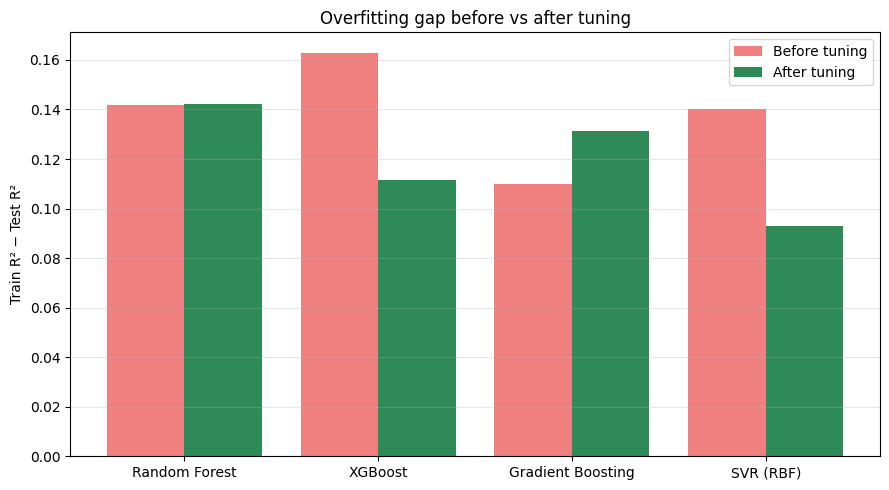

In [19]:
x = np.arange(len(before_after))

plt.figure(figsize=(9, 5))
plt.bar(x - 0.2, before_after["gap_before"], width=0.4, label="Before tuning", color="lightcoral")
plt.bar(x + 0.2, before_after["gap_after"], width=0.4, label="After tuning", color="seagreen")

plt.xticks(x, before_after.index)
plt.ylabel("Train R² − Test R²")
plt.title("Overfitting gap before vs after tuning")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
top2_tuned = tuned.sort_values("CV_R2", ascending=False).head(2)

print("Best 2 tuned models (by CV R²):")
print()
for rank, (name, row) in enumerate(top2_tuned.iterrows(), start=1):
    print(f"{rank}. {name}")
    print(f"   CV R2     : {row['CV_R2']:.4f} ± {row['CV_std']:.4f}")
    print(f"   Train R2  : {row['train_R2']:.4f}")
    print(f"   Test R2   : {row['test_R2']:.4f}")
    print(f"   Gap       : {row['gap']:.4f}")
    print(f"   Test RMSE : {row['test_RMSE']:.2f} MPa")
    print(f"   Test MAE  : {row['test_MAE']:.2f} MPa")
    print()

Best 2 tuned models (by CV R²):

1. Gradient Boosting
   CV R2     : 0.9030 ± 0.0092
   Train R2  : 0.9662
   Test R2   : 0.8348
   Gap       : 0.1314
   Test RMSE : 6.49 MPa
   Test MAE  : 4.47 MPa

2. XGBoost
   CV R2     : 0.9005 ± 0.0105
   Train R2  : 0.9681
   Test R2   : 0.8564
   Gap       : 0.1117
   Test RMSE : 6.05 MPa
   Test MAE  : 4.28 MPa

